In [1]:
import pandas as pd
import logging
from itertools import product, combinations

import sys
sys.path.append("..")

from utils import get_all_countries, get_empty_country_df
from network_analysis import get_networks
from community import detect_local_communities
from hegemony import get_hegemony_scores, get_hegemony_top, visualize_hegemony
from data_handling import gsheet_handler


ImportError: cannot import name 'get_all_countries' from 'utils' (unknown location)

In [3]:
import logging
logger = logging.getLogger()
logger.setLevel(logging.DEBUG)
logging.debug("test")

DEBUG:root:test


In [4]:
country_df = gsheet_handler.read_gsheet(tablename='country_data', sheetname='countryids', skiprows=0)

DEBUG:data_handling.gsheet_handler:1. try:
DEBUG:root:reading google table country_data, sheet countryids
DEBUG:google.auth.transport.requests:Making request: POST https://oauth2.googleapis.com/token
DEBUG:urllib3.connectionpool:Starting new HTTPS connection (1): oauth2.googleapis.com:443
DEBUG:urllib3.connectionpool:https://oauth2.googleapis.com:443 "POST /token HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:Starting new HTTPS connection (1): www.googleapis.com:443
DEBUG:urllib3.connectionpool:https://www.googleapis.com:443 "GET /drive/v3/files?q=mimeType%3D%22application%2Fvnd.google-apps.spreadsheet%22+and+name+%3D+%22country_data%22&pageSize=1000&supportsAllDrives=True&includeItemsFromAllDrives=True&fields=kind%2CnextPageToken%2Cfiles%28id%2Cname%2CcreatedTime%2CmodifiedTime%29 HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:Starting new HTTPS connection (1): sheets.googleapis.com:443
DEBUG:urllib3.connectionpool:https://sheets.googleapis.com:443 "GET /v4/spreadsheets/1-A17WUw0EPd

In [5]:
def load_interventions():
    """Loads DoCaNoMI data 1992-2022"""

    df = gsheet_handler.read_gsheet(tablename='interventions', sheetname='i_main', skiprows=1)

    logging.info("Loaded DoCaNoMI data 1992-2022")
    return df

In [6]:
df = load_interventions()

year_start = 1992
year_end = 2022
neighbourhood_value = 0.1
neighbourhood_type = 'region'

# removing non-cases
df = df[df['i_case']==1]
# removing cases marked for removal
df = df[~df['i_dyad_id'].str.contains('r')]



df['i_year_end']=df['i_year_end'].replace('ongoing', 2022)
df = df.dropna(subset=['i_year_end'])
df['i_year_end'] = df['i_year_end'].astype(int)
df['i_year_start'] = df['i_year_start'].astype(int)

df['year'] = df.apply(lambda row: list(range(row['i_year_start'], row['i_year_end']+1)), axis=1)
df = df.explode('year')

df['i_case'] = df['i_case'].astype(float)

#removing old data
df = df[df['year'] >= year_start]
df = df[['year', 'refobject_en', 'refsubject_en', 'i_case']]

df_triple = df.groupby(["year", "refobject_en", "refsubject_en"]).sum()
df_triple = df_triple[df_triple['i_case']!=0]

df_triple = pd.DataFrame(df_triple['i_case'])

# splitting up refobjects
df['refobject_en'] = df['refobject_en'].apply(lambda x: x.split("; "))
df = df.explode('refobject_en')
df['refobject_en'] = df['refobject_en'].apply(lambda x: x.strip())

countries_all = get_all_countries(df, ego_column = 'refsubject_en', alter_column = 'refobject_en')

empty_df=get_empty_country_df(years=df['year'].unique(), countries_all=countries_all, names=["year", "refsubject_en", "refobject_en"])

# multiplying with neighbourhood matrix
zero_df = empty_df.loc[year_start].reset_index()
if 'state_visual' in country_df.columns: country_df.set_index('state_visual', inplace=True)
country_df.loc['Yugoslavia'] = country_df.loc['Serbia']  # fix
zero_df['value'] = zero_df.apply(lambda x: neighbourhood_value if country_df.loc[x['refsubject_en'],'region_lowest_level'] == country_df.loc[x['refobject_en'],'region_lowest_level'] else 0, axis=1)
zero_df['year'] = [list(range(year_start, year_end+1)) for i in zero_df.index]
zero_df = zero_df.explode('year').set_index(['year', 'refsubject_en', 'refobject_en'])

df_triple = zero_df.merge(df_triple,left_index=True, right_index=True, how='outer').fillna(0)
df_triple['i_case'] = df_triple['i_case'] + df_triple['value']
df_triple.drop('value', axis=1, inplace=True)

DEBUG:data_handling.gsheet_handler:1. try:
DEBUG:root:reading google table interventions, sheet i_main
DEBUG:urllib3.connectionpool:https://www.googleapis.com:443 "GET /drive/v3/files?q=mimeType%3D%22application%2Fvnd.google-apps.spreadsheet%22+and+name+%3D+%22interventions%22&pageSize=1000&supportsAllDrives=True&includeItemsFromAllDrives=True&fields=kind%2CnextPageToken%2Cfiles%28id%2Cname%2CcreatedTime%2CmodifiedTime%29 HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:https://sheets.googleapis.com:443 "GET /v4/spreadsheets/1RM5ByxkVnf9TveX3v1zcMNy7o0MzSG21AvZlfXLOpgs?includeGridData=false HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:https://sheets.googleapis.com:443 "GET /v4/spreadsheets/1RM5ByxkVnf9TveX3v1zcMNy7o0MzSG21AvZlfXLOpgs?includeGridData=false HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:https://sheets.googleapis.com:443 "GET /v4/spreadsheets/1RM5ByxkVnf9TveX3v1zcMNy7o0MzSG21AvZlfXLOpgs/values/i_main?valueRenderOption=UNFORMATTED_VALUE&dateTimeRenderOption=FORMATTED_ST

In [7]:
df_triple.loc[2022].loc['Russia'][df_triple.loc[2022].loc['Russia']['i_case']>0]

,i_case
refobject_en,
Belarus,0.1
Bulgaria,0.1
Czech Republic,0.1
Czechoslovakia,0.1
Hungary,0.1
Kazakhstan,1.0
Moldova,0.1
Poland,0.1
Romania,0.1


In [8]:
df_triple.loc[2022]

i_case
refsubject_en refobject_en        
Afghanistan   Afghanistan      0.1
              Albania          0.0
              Angola           0.0
              Argentina        0.0
              Armenia          0.0
...                            ...
Zimbabwe      Uruguay          0.0
              Yemen            0.0
              Yugoslavia       0.0
              Zambia           0.1
              Zimbabwe         0.1

[18519 rows x 1 columns]

In [9]:
def preprocess_interventions(df, rolling_window=5, year_start=1992, year_end=2022, neighbourhood_value=0.1, neighbourhood_type='region'):
    """Preprocessing DoCaNoMI data:
        - removing non-cases
        - removing cases marked for removal
        - converting to time series format
        - converting to df in triple format (year*country*country)

    Parameters
    ------------
        df: pd.DataFrame()
            DataFrame with raw unprocessed DoCaNoMI Data
        rolling_window: int
            Rolling window to use for smoothing the data
        year_start: int
            Year to start with (needed for correct rolling calculations)
    Return
    -----------
        tuple(df , triple_df)
            df : pd.DataFramme() - preprocessed df with DoCaNoMI Data,
            triple_df  : pd.DataFramme() - DataFrame containing information about interventions in triple format (year*country*country). 
    """
    logging.info("Preprocessing DoCaNoMI Data")

    # removing non-cases
    df = df[df['i_case']==1]
    # removing cases marked for removal
    df = df[~df['i_dyad_id'].str.contains('r')]



    df['i_year_end']=df['i_year_end'].replace('ongoing', 2022)
    df = df.dropna(subset=['i_year_end'])
    df['i_year_end'] = df['i_year_end'].astype(int)
    df['i_year_start'] = df['i_year_start'].astype(int)
    
    df['year'] = df.apply(lambda row: list(range(row['i_year_start'], row['i_year_end']+1)), axis=1)
    df = df.explode('year')
    
    df['i_case'] = df['i_case'].astype(float)
    
    #removing old data
    df = df[df['year'] >= year_start]
    df = df[['year', 'refobject_en', 'refsubject_en', 'i_case']]
    
    df_triple = df.groupby(["year", "refobject_en", "refsubject_en"]).sum()
    df_triple = df_triple[df_triple['i_case']!=0]
    
    df_triple = pd.DataFrame(df_triple['i_case'])
    
    # splitting up refobjects
    df['refobject_en'] = df['refobject_en'].apply(lambda x: x.split("; "))
    df = df.explode('refobject_en')
    df['refobject_en'] = df['refobject_en'].apply(lambda x: x.strip())
    
    countries_all = get_all_countries(df, ego_column = 'refsubject_en', alter_column = 'refobject_en')
    
    empty_df=get_empty_country_df(years=df['year'].unique(), countries_all=countries_all, names=["year", "refsubject_en", "refobject_en"])
    
    # multiplying with neighbourhood matrix
    zero_df = empty_df.loc[year_start].reset_index()
    if 'state_visual' in country_df.columns: country_df.set_index('state_visual', inplace=True)
    country_df.loc['Yugoslavia'] = country_df.loc['Serbia']  # fix
    zero_df['value'] = zero_df.apply(lambda x: neighbourhood_value if country_df.loc[x['refsubject_en'],'region_lowest_level'] == country_df.loc[x['refobject_en'],'region_lowest_level'] else 0, axis=1)
    zero_df['year'] = [list(range(year_start, year_end+1)) for i in zero_df.index]
    zero_df = zero_df.explode('year').set_index(['year', 'refsubject_en', 'refobject_en'])
    
    df_triple = zero_df.merge(df_triple,left_index=True, right_index=True, how='outer').fillna(0)
    df_triple['i_case'] = df_triple['i_case'] + df_triple['value']
    df_triple.drop('value', axis=1, inplace=True)
    
    # counting rolling average
    df_triple = df_triple.reset_index().set_index('year').groupby(['refobject_en', 'refsubject_en']).rolling(rolling_window, min_periods=1).mean()
    
    df_triple = df_triple.reset_index().set_index(['year', 'refobject_en', 'refsubject_en'])
    
    df_triple.index.names = ['year', 'alter', 'ego']
    df_triple.rename(columns={'i_case':'value'}, inplace=True)
    
    logging.info("Done preprocessing DoCaNoMI Data")
    return df, df_triple

In [10]:
def interventions_main(year_start=1992, year_end=2022, rolling_window=5, 
                       res_range_start=2, res_range_end=20, one_year_hegemony_threshold=5, 
                       min_clients_for_top=3, centrality_threshold=0.5,
                       neighbourhood_value=0.1, community_detection='louvian'):
    comm_name = 'interventions'
    
    df = load_interventions() # Loading the data
    df, df_triple = preprocess_interventions(df, rolling_window=rolling_window, year_start=year_start, year_end=year_end, neighbourhood_value=neighbourhood_value)  # data preprocessing
    countries_all = get_all_countries(processed_df=df, ego_column = 'refsubject_en', alter_column = 'refobject_en')  # getting set of all countries
    year_end = df_triple.index.get_level_values('year').max()  # getting last year in df
    networks = get_networks(df_triple, countries_all, year_start, year_end)  # getting netowrks
    resolution_range = list(map(lambda x: x/10, list(range(res_range_start, res_range_end))))
    logging.debug(f"Resolution range is {resolution_range}")
    communities = detect_local_communities(networks, df_triple, countries_all, year_start, year_end, resolution_range, centrality_threshold=centrality_threshold, community_detection=community_detection)
    hegemony_df = get_hegemony_scores(communities, resolution_range, year_start, year_end, countries_all, comm_name=comm_name)
    all_time_threshold = (year_end - year_start) * min_clients_for_top
    hegemony_top = get_hegemony_top(hegemony_df, comm_name, one_year_threshold=one_year_hegemony_threshold, all_time_threshold=all_time_threshold)
    visualize_hegemony(hegemony_top, title = f"{comm_name}: top hegemons")
    return communities, hegemony_df, hegemony_top

DEBUG:data_handling.gsheet_handler:1. try:
DEBUG:root:reading google table interventions, sheet i_main
DEBUG:urllib3.connectionpool:https://www.googleapis.com:443 "GET /drive/v3/files?q=mimeType%3D%22application%2Fvnd.google-apps.spreadsheet%22+and+name+%3D+%22interventions%22&pageSize=1000&supportsAllDrives=True&includeItemsFromAllDrives=True&fields=kind%2CnextPageToken%2Cfiles%28id%2Cname%2CcreatedTime%2CmodifiedTime%29 HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:https://sheets.googleapis.com:443 "GET /v4/spreadsheets/1RM5ByxkVnf9TveX3v1zcMNy7o0MzSG21AvZlfXLOpgs?includeGridData=false HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:https://sheets.googleapis.com:443 "GET /v4/spreadsheets/1RM5ByxkVnf9TveX3v1zcMNy7o0MzSG21AvZlfXLOpgs?includeGridData=false HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:https://sheets.googleapis.com:443 "GET /v4/spreadsheets/1RM5ByxkVnf9TveX3v1zcMNy7o0MzSG21AvZlfXLOpgs/values/i_main?valueRenderOption=UNFORMATTED_VALUE&dateTimeRenderOption=FORMATTED_ST

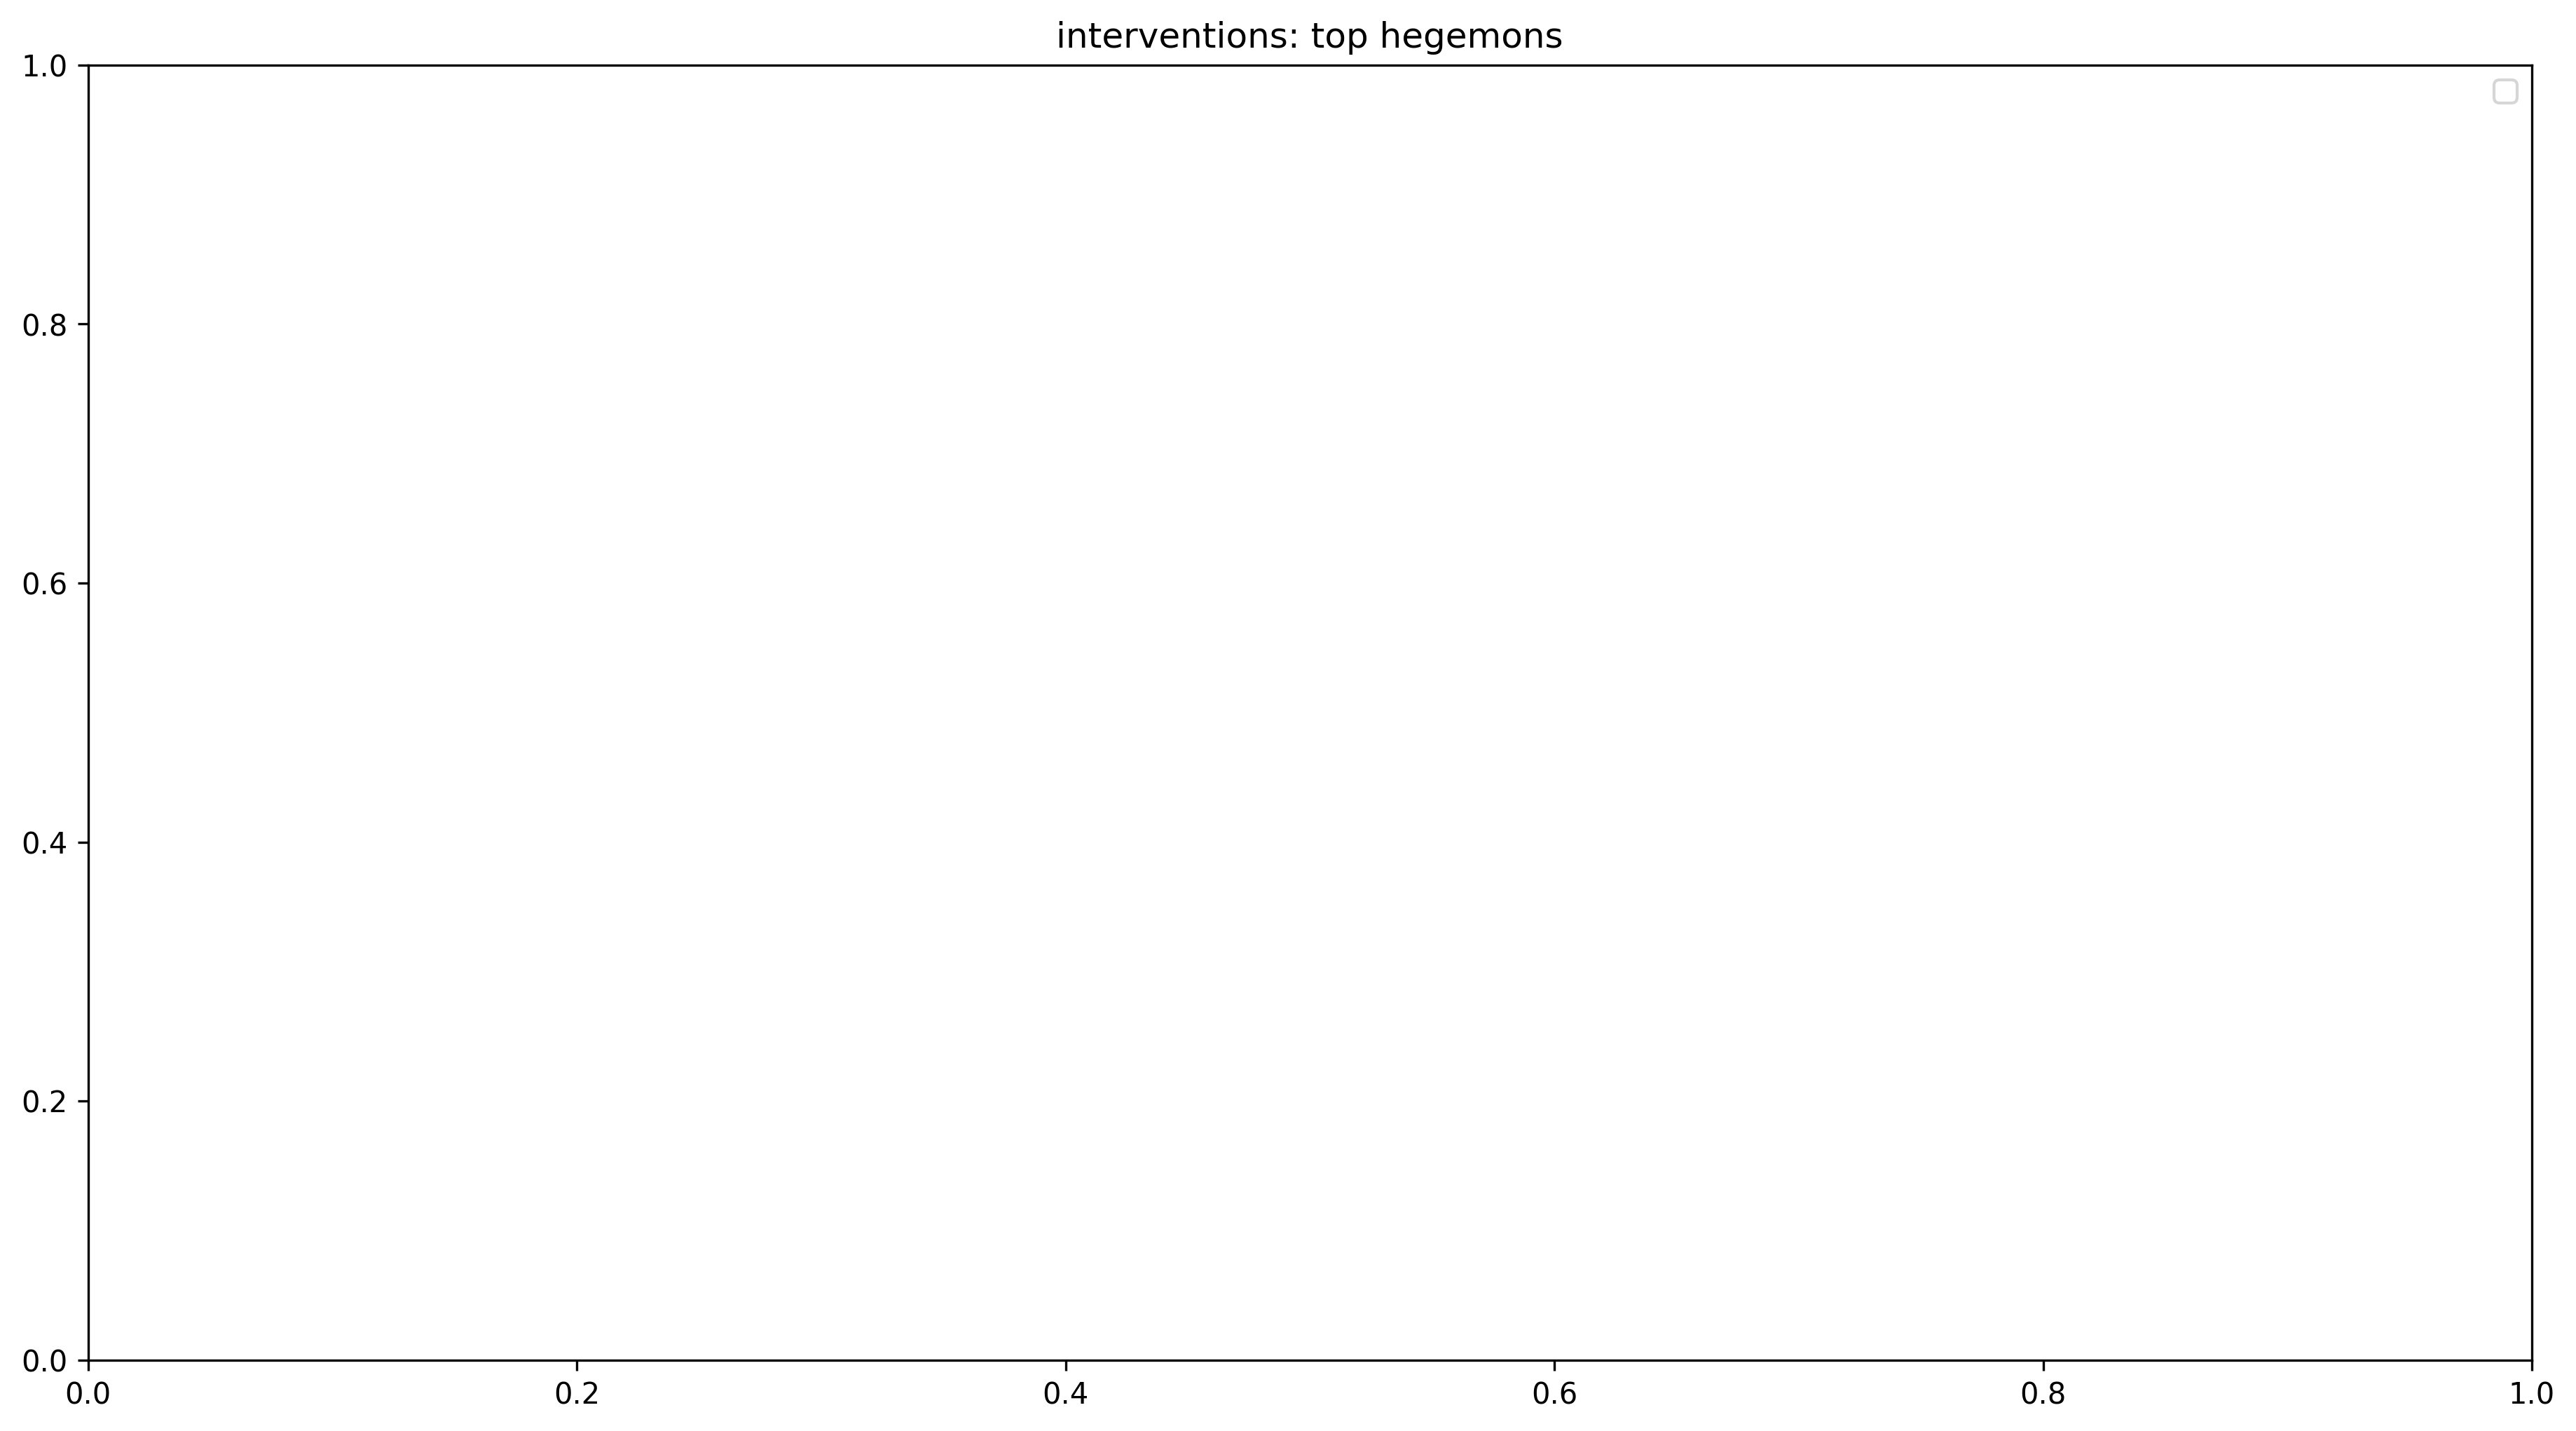

In [11]:
# идеи - убрать self-loop
# идеи - вручную сформировать communities
communities, hegemony_df, hegemony_top = interventions_main(rolling_window=20, min_clients_for_top=1, one_year_hegemony_threshold=2, res_range_start=0, res_range_end=1, neighbourhood_value=0.00001, community_detection='louvian')

In [12]:
countries_all = get_all_countries(df, ego_column = 'refsubject_en', alter_column = 'refobject_en')
empty_df=get_empty_country_df(years=df['i_case'].unique(), countries_all=countries_all, names=["year", "refsubject_en", "refobject_en"])

#empty_df.merge(df_triple,left_index=True, right_index=True, how='outer').fillna(0)

DEBUG:root:getting all countries for df
INFO:root:there are 136 unique countries, 119 - ego, 46 - alter


In [13]:
df['refobjeсt_en']

KeyError: 'refobjeсt_en'

In [14]:
list(combinations([df['refsubject_en'].unique(), df['refobjeсt_en'].unique(), range(1992,2022)], r=1))

KeyError: 'refobjeсt_en'

In [15]:
list(((ego,alter,year) for ego in df['refsubject_en'].unique() for alter in df['refobjeсt_en'].unique() for year in range(1992,2022)))


KeyError: 'refobjeсt_en'

In [ ]:
for ego, alter, year #in product([df['refsubject_en'].unique(), df['refobjeсt_en'].unique(), range(1992,2022)], repeat=1):
    print(ego, alter, year)

In [16]:
for country, year in zip()

SyntaxError: invalid syntax (2608267837.py, line 1)

In [17]:
import sipri # pip install sipri
import pandas as pd
import logging
from itertools import product, combinations

import sys
sys.path.append("..")

from utils import get_all_countries, get_empty_country_df
from network_analysis import get_networks
from community import detect_local_communities
from hegemony import get_hegemony_scores, get_hegemony_top, visualize_hegemony

SIPRI_PATH="data/sipri_arms_transfer_dyad_backup.csv"

def load_sipri():
    """Loads SIPRI Arms transfer data (last: 2022)"""
    #data = sipri.sipri_data(low_year='1985',high_year='2022',seller='',buyer='',armanent_category='any',buyers_or_sellers='',filetype='csv',include_open_deals='on',sum_deliveries='on')
    #df = pd.read_csv(StringIO(data),keep_default_na=False,na_values=['None'])
    #df.to_csv("sipri_arms_transfer_dyad.csv")
    df = pd.read_csv(SIPRI_PATH, index_col = 'Unnamed: 0')
    logging.info("Loaded SIPRI Arms Transfer Data")
    return df

def preprocess_sipri(df, rolling_window=5, year_start=1992):
    """Preprocessing SIPRI Arms Transfer Data:
        - removing rebel groups and international organizations
        - removing unknown recipients and suppliers
        - converting to df in triple format (year*country*country)

    Parameters
    ------------
        df: pd.DataFrame()
            DataFrame with raw unprocessed SIPRI Arms Transfer Data
        rolling_window: int
            Rolling window to use for smoothing the data
        year_start: int
            Year to start with (needed for correct rolling calculations)
    Return
    -----------
        tuple(df , triple_df)
            df : pd.DataFramme() - preprocessed df with SIPRI Arms Transfer Data,
            triple_df  : pd.DataFramme() - DataFrame containing information about Arms Transfer in triple format (year*country*country). 
    """
    logging.info("Preprocessing SIPRI Arms Transfer Data")
    df.drop(df.shape[0]-1, inplace=True)

    # removing rebel groups and IOs
    df = df[~df['buyer'].str.contains('\*')]
    # removing unknown recipients and suppliers
    df = df[~df['buyer'].str.contains('unknown')]
    df = df[~df['seller'].str.contains('\*')]
    df = df[~df['seller'].str.contains('unknown')]
    
    #buyers_all = df['buyer'].unique()
    #sellers_all = df['seller'].unique()
    #countries_all = set(list(buyers_all) + list(sellers_all))
    
    df['tivorder'] = df['tivorder'].astype(float)
    
    #removing old data
    df = df[df['odat'] >= year_start]
    
    countries_all = get_all_countries(df)
    
    df_triple = df.groupby(["odat", "buyer", "seller"]).sum()
    df_triple = df_triple[df_triple['tivorder']!=0]
    
    df_triple = pd.DataFrame(df_triple['tivorder'])

    

    # filling an empty year*country*country dataframe with zeroes
    #options = product(df['odat'].unique(),countries_all, countries_all)
    #index = pd.MultiIndex.from_tuples(options, names=["odat", "seller", "buyer"])
    #empty_df = pd.DataFrame(index=index)
    empty_df=get_empty_country_df(years=df['odat'].unique(), countries_all=countries_all, names=["odat", "seller", "buyer"])

    
    # merging the df with zero df
    df_triple = empty_df.merge(df_triple,left_index=True, right_index=True, how='outer').fillna(0)

    
    # counting rolling average
    df_triple = df_triple.reset_index().set_index('odat').groupby(['buyer', 'seller']).rolling(rolling_window, min_periods=1).mean()

    df_triple = df_triple.reset_index().set_index(['odat', 'buyer', 'seller'])
    
    df_triple.index.names = ['year', 'alter', 'ego']
    df_triple.rename(columns={'tivorder':'value'}, inplace=True)
    
    logging.info("Done preprocessing SIPRI Arms Transfer Data")
    return df, df_triple


    
def sipri_main(year_start=1992, rolling_window=5, res_range_start=2, res_range_end=20, one_year_hegemony_threshold=5, min_clients_for_top=3, centrality_threshold=0.5):
    comm_name = 'weapon_trade'
    
    df = load_sipri()  # Loading the data
    df, df_triple = preprocess_sipri(df, rolling_window=rolling_window, year_start=year_start)  # data preprocessing
    countries_all = get_all_countries(processed_df=df)  # getting set of all countries
    year_end = df_triple.index.get_level_values('year').max()  # getting last year in df
    networks = get_networks(df_triple, countries_all, year_start, year_end)  # getting netowrks
    resolution_range = list(map(lambda x: x/10, list(range(res_range_start, res_range_end))))
    logging.debug(f"Resolution range is {resolution_range}")
    communities = detect_local_communities(networks, df_triple, countries_all, year_start, year_end, resolution_range, centrality_threshold=centrality_threshold)
    hegemony_df = get_hegemony_scores(communities, resolution_range, year_start, year_end, countries_all, comm_name=comm_name)
    all_time_threshold = (year_end - year_start) * min_clients_for_top
    hegemony_top = get_hegemony_top(hegemony_df, comm_name, one_year_threshold=one_year_hegemony_threshold, all_time_threshold=all_time_threshold)
    visualize_hegemony(hegemony_top, title = f"{comm_name}: top hegemons")
    return communities, hegemony_df, hegemony_top

In [18]:
SIPRI_PATH="../data/sipri_arms_transfer_dyad_backup.csv"
df = pd.read_csv(SIPRI_PATH, index_col = 'Unnamed: 0')
logging.info("Loaded SIPRI Arms Transfer Data")
df

INFO:root:Loaded SIPRI Arms Transfer Data


,tidn,buyercod,sellercod,odat,odai,onum,onai,ldat,term,desig2,...,coprod,nrdel,nrdelai,delyears,buyer,seller,status,tivunit,tivorder,tivdel
0,55238,BF,ALB,2011,X,12.0,X,2011,NaN,PM-43 120mm,...,L,12.0,NaN,2011,Burkina Faso,Albania,S,0.02,0.24,0.24
1,60840,SAH,ALG,2016,X,3.0,X,2016,AID,BTR-60PB,...,L,3.0,X,2016,Western Sahara,Algeria,S,0.10,0.30,0.30
2,33777,IVO,ANG,2002,NaN,2.0,X,2002,NaN,BMP-2,...,L,2.0,X,2002,Cote d'Ivoire,Angola,S,0.36,0.72,0.72
3,33871,IVO,ANG,2002,NaN,2.0,NaN,2002,NaN,T-55,...,L,2.0,NaN,2002,Cote d'Ivoire,Angola,S,0.50,1.00,1.00
4,31645,BOL,ARG,2006,NaN,37.0,X,2006,AID,M-3/M-5 Half-track,...,L,37.0,X,2006,Bolivia,Argentina,S,0.06,2.22,2.22
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16480,26205,MEX,YUG,1985,X,8.0,NaN,1985,NaN,M-56 105mm,...,L,8.0,X,1985,Mexico,Yugoslavia,N,0.45,3.60,3.60
16481,20137,MYA,YUG,1990,NaN,6.0,X,1991,NaN,G-4 Super Galeb,...,L,6.0,NaN,1991,Myanmar,Yugoslavia,N,5.35,32.10,32.10
16482,54569,MYA,YUG,1990,NaN,3.0,NaN,1990,NaN,PB-90,...,L,3.0,NaN,1990,Myanmar,Yugoslavia,N,5.50,16.50,16.50
16483,19997,LIB,ZAM,1989,NaN,1.0,NaN,1990,NaN,DHC-4 Caribou,...,L,1.0,NaN,1990,Liberia,Zambia,S,1.50,1.50,1.50


In [21]:
import pandas as pd
import io
import networkx as nx
from io import StringIO
from itertools import product, combinations
from matplotlib import pyplot as plt

from community import Community, Hegemon, analyse_local_community, detect_local_communities
from network_analysis import get_networks#, countCentrality, get_network_from_year_df

from data_handling import sipri
from hegemony import get_hegemony_scores, get_hegemony_top, visualize_hegemony
from utils import get_all_countries, get_empty_country_df

In [22]:
communities, hegemony_df, hegemony_top=sipri.sipri_main(rolling_window=7)

FileNotFoundError: [Errno 2] No such file or directory: 'data/sipri_arms_transfer_dyad_backup.csv'

In [23]:
comm_name = 'weapon_trade'
    
#df = load_sipri()  # Loading the data
SIPRI_PATH="../data/sipri_arms_transfer_dyad_backup.csv"
df = pd.read_csv(SIPRI_PATH, index_col = 'Unnamed: 0')

df, df_triple = preprocess_sipri(df, rolling_window=rolling_window, year_start=year_start)  # data preprocessing
countries_all = get_all_countries(processed_df=df)  # getting set of all countries
year_end = df_triple.index.get_level_values('year').max()  # getting last year in df
networks = get_networks(df_triple, countries_all, year_start, year_end)  # getting netowrks
resolution_range = list(map(lambda x: x/10, list(range(res_range_start, res_range_end))))
logging.debug(f"Resolution range is {resolution_range}")
communities = detect_local_communities(networks, df_triple, countries_all, year_start, year_end, resolution_range, centrality_threshold=centrality_threshold)
hegemony_df = get_hegemony_scores(communities, resolution_range, year_start, year_end, countries_all, comm_name=comm_name)
all_time_threshold = (year_end - year_start) * min_clients_for_top
hegemony_top = get_hegemony_top(hegemony_df, comm_name, one_year_threshold=one_year_hegemony_threshold, all_time_threshold=all_time_threshold)
visualize_hegemony(hegemony_top, title = f"{comm_name}: top hegemons")
#return communities, hegemony_df, hegemony_top

INFO:root:Preprocessing SIPRI Arms Transfer Data
DEBUG:root:getting all countries for df
INFO:root:there are 187 unique countries, 106 - ego, 186 - alter
INFO:root:Done preprocessing SIPRI Arms Transfer Data
DEBUG:root:getting all countries for df
INFO:root:there are 187 unique countries, 106 - ego, 186 - alter
INFO:root:Getting global networks for 1992 - 2022
DEBUG:root:Getting networks for 1992
DEBUG:root:Getting networks for 1993
DEBUG:root:Getting networks for 1994
DEBUG:root:Getting networks for 1995
DEBUG:root:Getting networks for 1996
DEBUG:root:Getting networks for 1997
DEBUG:root:Getting networks for 1998
DEBUG:root:Getting networks for 1999
DEBUG:root:Getting networks for 2000
DEBUG:root:Getting networks for 2001
DEBUG:root:Getting networks for 2002
DEBUG:root:Getting networks for 2003
DEBUG:root:Getting networks for 2004
DEBUG:root:Getting networks for 2005
DEBUG:root:Getting networks for 2006
DEBUG:root:Getting networks for 2007
DEBUG:root:Getting networks for 2008
DEBUG:ro

NotImplementedError: out-degree

In [ ]:
df_triple

In [ ]:
def preprocess_interventions(df, rolling_window=5, year_start=1992):
    """Preprocessing DoCaNoMI data:
        - removing non-cases
        - removing cases marked for removal
        - converting to time series format
        - converting to df in triple format (year*country*country)

    Parameters
    ------------
        df: pd.DataFrame()
            DataFrame with raw unprocessed DoCaNoMI Data
        rolling_window: int
            Rolling window to use for smoothing the data
        year_start: int
            Year to start with (needed for correct rolling calculations)
    Return
    -----------
        tuple(df , triple_df)
            df : pd.DataFramme() - preprocessed df with DoCaNoMI Data,
            triple_df  : pd.DataFramme() - DataFrame containing information about interventions in triple format (year*country*country). 
    """
    logging.info("Preprocessing DoCaNoMI Data")
    

    # removing non-cases
    df = df[df['i_case']==1]
    # removing cases marked for removal
    df = df[~df['i_dyad_id'].str.contains('r')]

    return df
    
    df['tivorder'] = df['tivorder'].astype(float)
    
    #removing old data
    df = df[df['odat'] >= year_start]
    
    countries_all = get_all_countries(df)
    
    df_triple = df.groupby(["odat", "buyer", "seller"]).sum()
    df_triple = df_triple[df_triple['tivorder']!=0]
    
    df_triple = pd.DataFrame(df_triple['tivorder'])

    

    # filling an empty year*country*country dataframe with zeroes
    #options = product(df['odat'].unique(),countries_all, countries_all)
    #index = pd.MultiIndex.from_tuples(options, names=["odat", "seller", "buyer"])
    #empty_df = pd.DataFrame(index=index)
    empty_df=get_empty_country_df(years=df['odat'].unique(), countries_all=countries_all, names=["odat", "seller", "buyer"])

    
    # merging the df with zero df
    df_triple = empty_df.merge(df_triple,left_index=True, right_index=True, how='outer').fillna(0)

    
    # counting rolling average
    df_triple = df_triple.reset_index().set_index('odat').groupby(['buyer', 'seller']).rolling(rolling_window, min_periods=1).mean()

    df_triple = df_triple.reset_index().set_index(['odat', 'buyer', 'seller'])
    
    df_triple.index.names = ['year', 'alter', 'ego']
    df_triple.rename(columns={'tivorder':'value'}, inplace=True)
    
    logging.info("Done preprocessing SIPRI Arms Transfer Data")
    return df, df_triple


    
def sipri_main(year_start=1992, rolling_window=5, res_range_start=2, res_range_end=20, one_year_hegemony_threshold=5, min_clients_for_top=3, centrality_threshold=0.5):
    comm_name = 'weapon_trade'
    
    df = load_sipri()  # Loading the data
    df, df_triple = preprocess_sipri(df, rolling_window=rolling_window, year_start=year_start)  # data preprocessing
    countries_all = get_all_countries(processed_df=df)  # getting set of all countries
    year_end = df_triple.index.get_level_values('year').max()  # getting last year in df
    networks = get_networks(df_triple, countries_all, year_start, year_end)  # getting netowrks
    resolution_range = list(map(lambda x: x/10, list(range(res_range_start, res_range_end))))
    logging.debug(f"Resolution range is {resolution_range}")
    communities = detect_local_communities(networks, df_triple, countries_all, year_start, year_end, resolution_range, centrality_threshold=centrality_threshold)
    hegemony_df = get_hegemony_scores(communities, resolution_range, year_start, year_end, countries_all, comm_name=comm_name)
    all_time_threshold = (year_end - year_start) * min_clients_for_top
    hegemony_top = get_hegemony_top(hegemony_df, comm_name, one_year_threshold=one_year_hegemony_threshold, all_time_threshold=all_time_threshold)
    visualize_hegemony(hegemony_top, title = f"{comm_name}: top hegemons")
    return communities, hegemony_df, hegemony_top

In [7]:
import sipri # pip install sipri
import pandas as pd
import logging
from itertools import product, combinations

import sys
sys.path.append("..")

from utils import get_all_countries, get_empty_country_df
from network_analysis import get_networks
from community import detect_local_communities
from hegemony import get_hegemony_scores, get_hegemony_top, visualize_hegemony
from countryconverter import convert_country_df
from data_handling import gsheet_handler

from sipri import load_sipri, preprocess_sipri
from interventions import load_interventions, preprocess_interventions

def analysis_main(year_start=1992, rolling_window=5, res_range_start=2, res_range_end=20, one_year_hegemony_threshold=5, min_clients_for_top=3, centrality_threshold=0.5, community_detection='louvian'):
    
    weapon_df = load_sipri()  # Loading the data
    weapon_df, weapon_df_triple = preprocess_sipri(weapon_df, rolling_window=rolling_window, year_start=year_start)  # data preprocessing

    intervention_df = load_interventions()
    intervention_df, intervention_df_triple = preprocess_interventions(intervention_df, rolling_window=rolling_window, year_start=year_start)  # data preprocessing

In [8]:
%load_ext autoreload

In [9]:
%autoreload 2

In [58]:
weapon_df = load_sipri()  # Loading the data
weapon_df, weapon_df_triple = preprocess_sipri(weapon_df, rolling_window=5, year_start=1992)  # data preprocessing

/home/alex-server/Sync/Работа/Code/network_analysis/data_handling/../countryconverter.py:75: UserWarning: Unknown identifier Kosovo, keeping as is
  if warning: warnings.warn(f"Unknown identifier {country}, keeping as is")
/home/alex-server/Sync/Работа/Code/network_analysis/data_handling/../countryconverter.py:75: UserWarning: Unknown identifier Western Sahara, keeping as is
  if warning: warnings.warn(f"Unknown identifier {country}, keeping as is")
/home/alex-server/Sync/Работа/Code/network_analysis/data_handling/../countryconverter.py:75: UserWarning: Unknown identifier Taiwan, keeping as is
  if warning: warnings.warn(f"Unknown identifier {country}, keeping as is")
/home/alex-server/Sync/Работа/Code/network_analysis/data_handling/../countryconverter.py:75: UserWarning: Unknown identifier Northern Cyprus, keeping as is
  if warning: warnings.warn(f"Unknown identifier {country}, keeping as is")
/home/alex-server/Sync/Работа/Code/network_analysis/data_handling/../countryconverter.py:75

In [7]:
intervention_df = load_interventions()
intervention_df, intervention_df_triple = preprocess_interventions(intervention_df, rolling_window=5, year_start=1992, neighbourhood_type=None)  # data preprocessing

In [5]:
df = intervention_df_triple + weapon_df_triple

In [9]:
intervention_df_triple.sort_values('value')

,,,value
year,alter,ego,
1992,Afghanistan,Afghanistan,0.0
1994,Pakistan,Nicaragua,0.0
1995,Pakistan,Nicaragua,0.0
1996,Pakistan,Nicaragua,0.0
1997,Pakistan,Nicaragua,0.0
...,...,...,...
2021,Syrian Arab Republic,"Iran, Islamic Republic of",1.0
2020,Syrian Arab Republic,"Iran, Islamic Republic of",1.0
2019,Syrian Arab Republic,"Iran, Islamic Republic of",1.0


In [8]:
intervention_df_triple.sort_values('value')

,,,value
year,alter,ego,
1992,Afghanistan,Afghanistan,0.0
1994,Pakistan,Nicaragua,0.0
1995,Pakistan,Nicaragua,0.0
1996,Pakistan,Nicaragua,0.0
1997,Pakistan,Nicaragua,0.0
...,...,...,...
2021,Syrian Arab Republic,"Iran, Islamic Republic of",1.0
2020,Syrian Arab Republic,"Iran, Islamic Republic of",1.0
2019,Syrian Arab Republic,"Iran, Islamic Republic of",1.0


In [6]:
weapon_df_triple.reset_index()['alter'].unique()#==weapon_df_triple.reset_index()['year'].unique()

array(['Afghanistan', 'Albania', 'Algeria', 'Andorra', 'Angola',
       'Antigua and Barbuda', 'Argentina', 'Armenia', 'Australia',
       'Austria', 'Azerbaijan', 'Bahamas', 'Bahrain', 'Bangladesh',
       'Barbados', 'Belarus', 'Belgium', 'Belize', 'Benin', 'Bhutan',
       'Bolivia (Plurinational State of)', 'Bosnia and Herzegovina',
       'Botswana', 'Brazil', 'Brunei Darussalam', 'Bulgaria',
       'Burkina Faso', 'Burundi', 'Cabo Verde', 'Cambodia', 'Cameroon',
       'Canada', 'Central African Republic', 'Chad', 'Chile',
       "China, People's Republic of", 'Colombia', 'Comoros', 'Congo',
       'Costa Rica', 'Croatia', 'Cuba', 'Cyprus', 'Czechia',
       "Côte d'Ivoire", "Democratic People's Republic of Korea",
       'Democratic Republic of the Congo', 'Denmark', 'Djibouti',
       'Dominica', 'Dominican Republic', 'Ecuador', 'Egypt',
       'El Salvador', 'Equatorial Guinea', 'Eritrea', 'Estonia',
       'Ethiopia', 'Fiji', 'Finland', 'France', 'Gabon', 'Gambia',
       'Ge

In [9]:
df.sort_values(['value'])

,,,value
year,alter,ego,
1992,Afghanistan,Afghanistan,0.0
1997,Oman,Venezuela (Bolivarian Republic of),0.0
1998,Oman,Venezuela (Bolivarian Republic of),0.0
1999,Oman,Venezuela (Bolivarian Republic of),0.0
2000,Oman,Venezuela (Bolivarian Republic of),0.0
...,...,...,...
2019,Syrian Arab Republic,"Iran, Islamic Republic of",1.0
2020,Syrian Arab Republic,"Iran, Islamic Republic of",1.0
2018,Syrian Arab Republic,"Iran, Islamic Republic of",1.0


In [1]:
from main import analysis_main

/home/alex-server/Sync/Работа/Code/network_analysis/data_handling/../countryconverter.py:75: UserWarning: Unknown identifier Western Sahara, keeping as is
  if warning: warnings.warn(f"Unknown identifier {country}, keeping as is")
/home/alex-server/Sync/Работа/Code/network_analysis/data_handling/../countryconverter.py:75: UserWarning: Unknown identifier Northern Cyprus, keeping as is
  if warning: warnings.warn(f"Unknown identifier {country}, keeping as is")
/home/alex-server/Sync/Работа/Code/network_analysis/data_handling/../countryconverter.py:75: UserWarning: Unknown identifier Palestine, keeping as is
  if warning: warnings.warn(f"Unknown identifier {country}, keeping as is")
/home/alex-server/Sync/Работа/Code/network_analysis/data_handling/../countryconverter.py:75: UserWarning: Unknown identifier Kosovo, keeping as is
  if warning: warnings.warn(f"Unknown identifier {country}, keeping as is")
/home/alex-server/Sync/Работа/Code/network_analysis/data_handling/../countryconverter.py

YEAR END TRADE 2022
YEAR END INT 2022
YEAR END = 2022


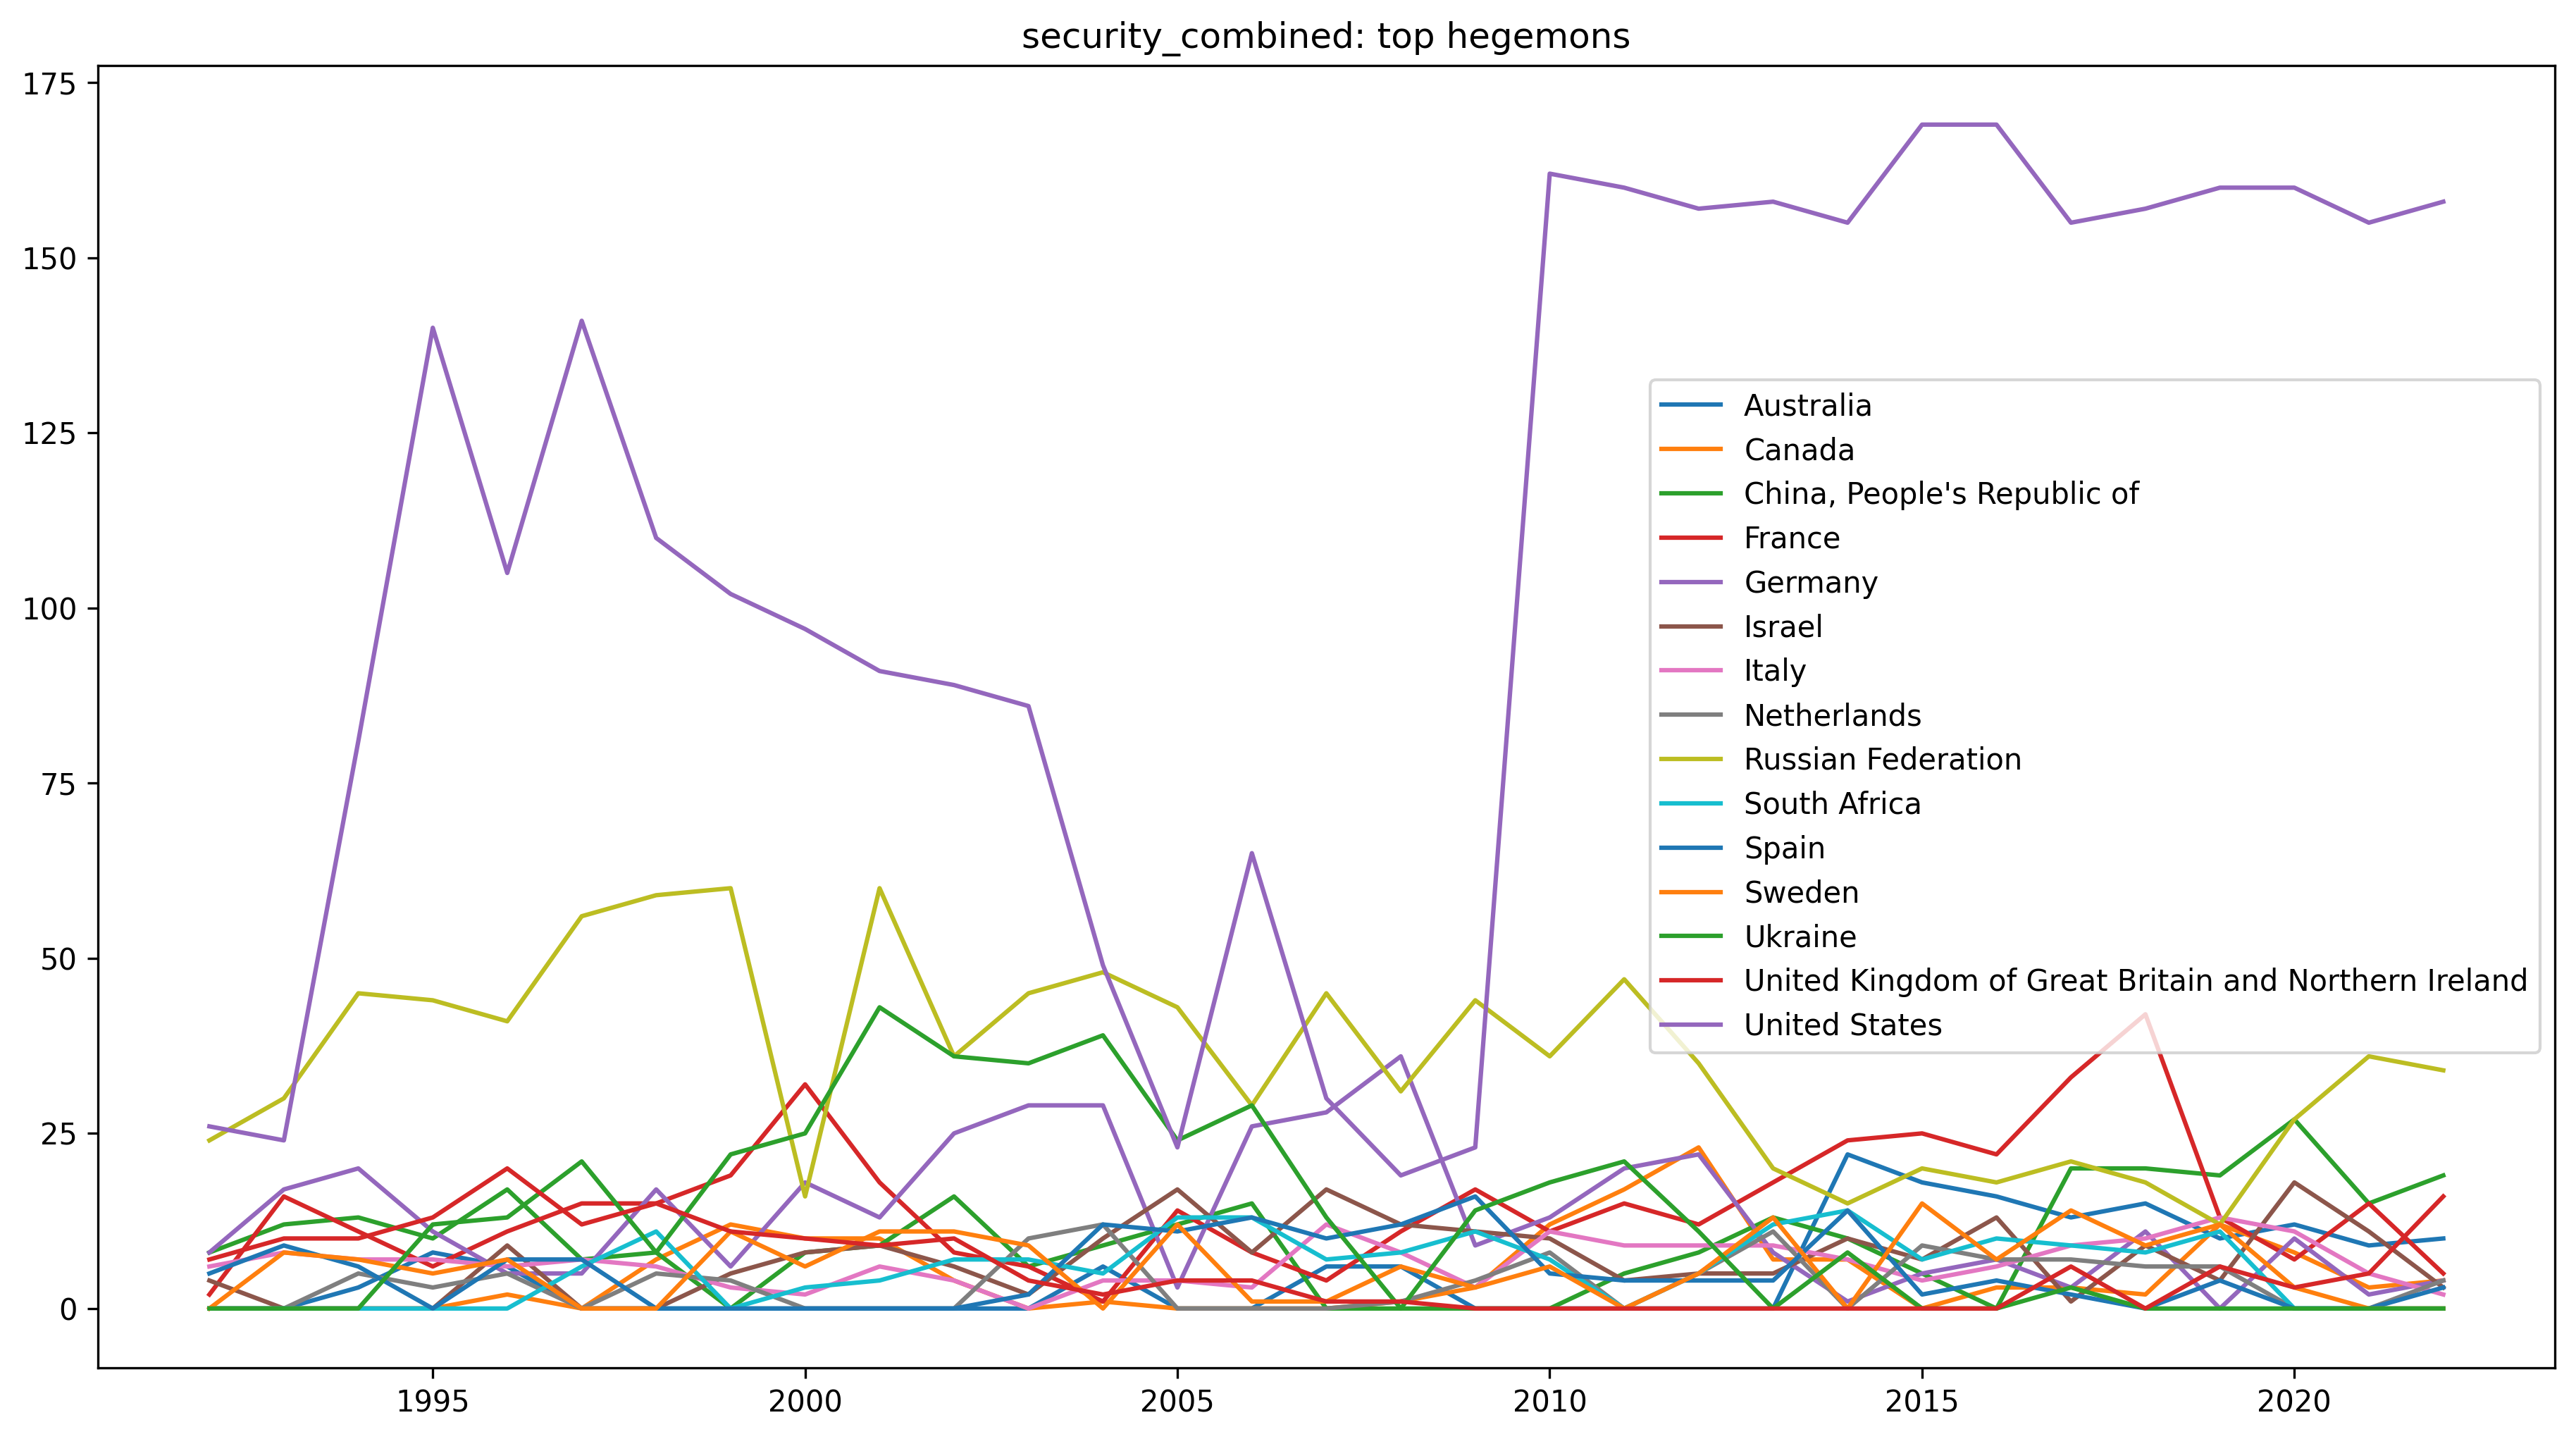

In [2]:
df_triple, communities, hegemony_df, hegemony_top = analysis_main(hierarchy_threshold=0, gdp_threshold=0.9, one_year_hegemony_threshold=3, min_clients_for_top=3)

In [3]:
df_triple.to_csv('../output/mil_hegemony_data.csv')

In [6]:
hegemony_df.to_csv('../output/mil_hegemony_result.csv')

In [5]:
hegemony_df.loc[2022].sort_values('security_combined')

security_combined
ego                              alter                        
Iceland                          Iceland                   0.0
Micronesia (Federated States of) Spain                     0.0
                                 Armenia                   0.0
                                 Nigeria                   0.0
                                 Bangladesh                0.0
...                                                        ...
United States                    Botswana                 18.0
                                 Georgia                  18.0
                                 Paraguay                 18.0
                                 Belize                   18.0
                                 Montenegro               18.0

[37249 rows x 1 columns]

In [23]:
hegemony_top['alter'][2021].sort_values()

ego
South Africa                                              0.0
Spain                                                     0.0
Ukraine                                                   0.0
Canada                                                    2.0
Italy                                                     3.0
United Kingdom of Great Britain and Northern Ireland      4.0
Israel                                                    5.0
Sweden                                                    6.0
Australia                                                11.0
Germany                                                  12.0
France                                                   17.0
China, People's Republic of                              19.0
Russian Federation                                       39.0
United States                                           155.0
Name: 2021, dtype: float64

In [40]:
hegemony_df[hegemony_df['security_combined']>3].loc[2021].reset_index().groupby('ego').count()['alter'].sort_values(ascending=False).to_csv('2021_top.csv')

/home/alex-server/Sync/Работа/Code/network_analysis/data_handling/../countryconverter.py:75: UserWarning: Unknown identifier Palestine, keeping as is
  if warning: warnings.warn(f"Unknown identifier {country}, keeping as is")
/home/alex-server/Sync/Работа/Code/network_analysis/data_handling/../countryconverter.py:75: UserWarning: Unknown identifier Taiwan, keeping as is
  if warning: warnings.warn(f"Unknown identifier {country}, keeping as is")
/home/alex-server/Sync/Работа/Code/network_analysis/data_handling/../countryconverter.py:75: UserWarning: Unknown identifier Kosovo, keeping as is
  if warning: warnings.warn(f"Unknown identifier {country}, keeping as is")
/home/alex-server/Sync/Работа/Code/network_analysis/data_handling/../countryconverter.py:75: UserWarning: Unknown identifier Northern Cyprus, keeping as is
  if warning: warnings.warn(f"Unknown identifier {country}, keeping as is")
/home/alex-server/Sync/Работа/Code/network_analysis/data_handling/../countryconverter.py:75: Use

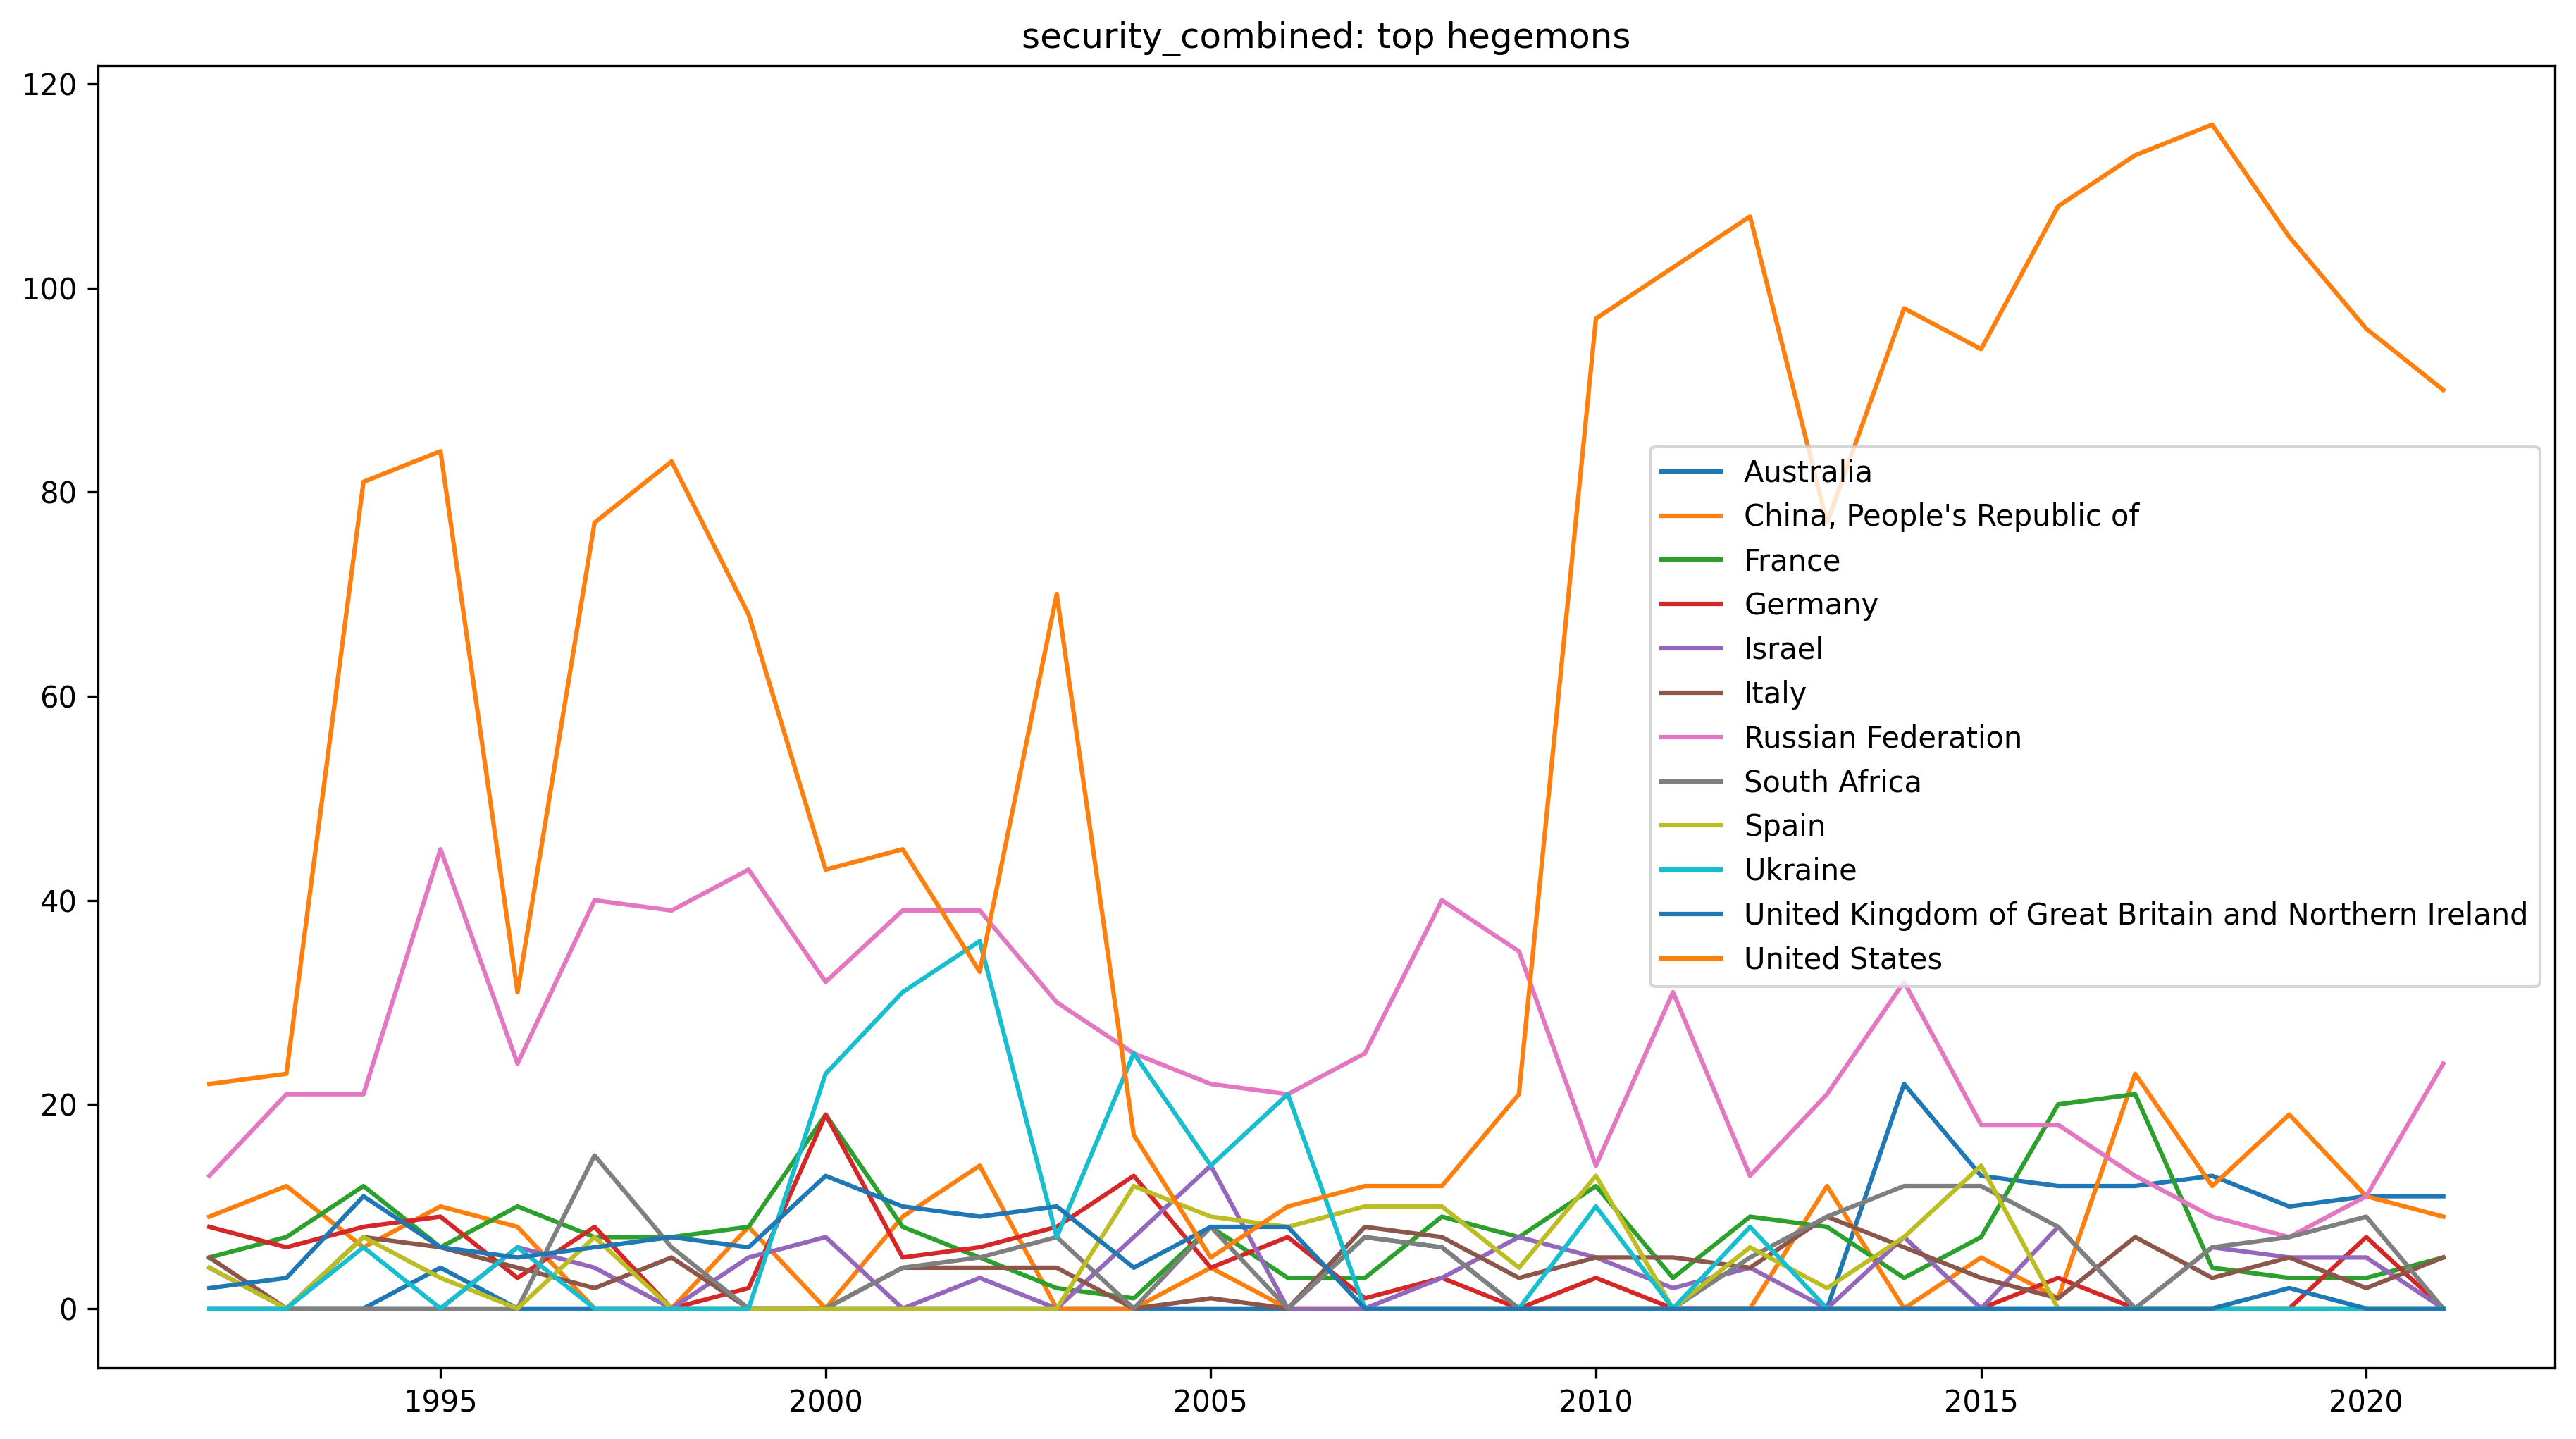

({1992: {0.2: [1992 Community at resolution 0.02 of 99 with None as hegemon (hierarchy score = 0.7917534360683048).
    The members are ['Angola', 'Mauritius', 'Fiji', 'India', 'Egypt', 'Israel', 'Sweden', 'Botswana', 'Mexico', 'South Africa', 'Panama', 'Ukraine', 'United States', 'Saudi Arabia', 'Colombia', 'Nigeria', 'Pakistan', 'Italy', 'Latvia', 'Rwanda', 'Iran, Islamic Republic of', 'Russian Federation', 'Kuwait', 'Oman', 'United Arab Emirates', 'Ecuador', 'Australia', 'Algeria', 'Republic of Korea', 'Philippines', 'Poland', 'Türkiye', 'Norway', 'Denmark', 'Djibouti', 'Guatemala', 'Lithuania', 'Czechia', 'Kiribati', 'Hungary', 'Eritrea', 'Qatar', 'Slovakia', 'Switzerland', 'Nepal', 'Syrian Arab Republic', 'Nicaragua', 'Croatia', 'Bulgaria', 'Tuvalu', 'Mauritania', 'Iraq', 'Malaysia', 'Portugal', 'Japan', 'Malta', 'Namibia', 'Cabo Verde', 'Uruguay', 'Finland', 'Bosnia and Herzegovina', 'Somalia', 'Bolivia (Plurinational State of)', 'Chile', 'Guinea-Bissau', 'Romania', 'Slovenia', '

In [2]:
analysis_main()

In [5]:
import sipri # pip install sipri
import pandas as pd
import logging
from itertools import product, combinations

import sys
sys.path.append("..")

from utils import get_all_countries, get_empty_country_df
from network_analysis import get_networks
from community import detect_local_communities
from hegemony import get_hegemony_scores, get_hegemony_top, visualize_hegemony
from countryconverter import convert_country_df
from data_handling import gsheet_handler



In [6]:
JME_PATH="../data/jmeDataPublic.xlsx"

"""Loads Joint Military Exercises data"""
df = pd.read_excel(JME_PATH)
logging.info("Loaded Joint Military Exercises data")

    
data_triple = []
year_start=1992
rolling_window=None
res_range_start=2
res_range_end=20
rolling_window=5
one_year_hegemony_threshold=5
             
min_clients_for_top=3
centrality_threshold=0.45
centrality_type='out-degree'
def _analyse_dyads(coparticipants_column: pd.Series, data_triple):
    """Add triple "country * country * year" data from a column into a global list

    Parameters
    ------------
        coparticipants_column: pd.Series
            A Series containing participants of one exercies
           
    """
    year = coparticipants_column.name[0]
    for dyad in combinations(coparticipants_column['countryName'].values, 2):  # US testing shows too little US, but maybe they will be on network level
    #for dyad in product(coparticipants_column['countryName'].values, repeat=2): # doubts, it might be excessive
        if dyad[0] != dyad[1]:
            #if 'United States' in dyad: print(year, dyad)
            dyad = list(dyad)
            data_triple += ((year, *dyad)),
            dyad.reverse()
            data_triple += ((year, *dyad)),
            #print(data_triple[-2], data_triple[-1])
# getting year * exerciseId * country data configuration
dyad_df = pd.DataFrame(df.groupby(['startYear', 'xID', 'countryName'])['startMonth'].count()).reset_index().drop('startMonth', axis=1).set_index(['startYear', 'xID'])
countries_all = get_all_countries()

dyad_df.reset_index(inplace=True)
dyad_df=dyad_df[dyad_df['startYear']>=year_start]
dyad_df.groupby(['startYear','xID']).apply(lambda x: _analyse_dyads(x, data_triple))
df_triple = pd.DataFrame(data_triple, columns = ['year', 'ego', 'alter'])
df_triple['value'] = 1
df_triple = df_triple.groupby(['year', 'ego', 'alter']).count()


In [7]:
## ОБЩЕЕ -------------------------------------------------------------------------------------------

df_triple.reset_index(inplace=True)

#converting to STATE_en_UN (can do Alpha3_Code)
df_triple = convert_country_df(df_triple, 'alter', standard_to_convert='STATE_en_UN', purge=True)
df_triple = convert_country_df(df_triple, 'ego', standard_to_convert='STATE_en_UN', purge=True)

df_triple.set_index(['year', 'ego', 'alter'], inplace=True)

empty_df=get_empty_country_df(years=df_triple.reset_index()['year'].unique(), countries_all=countries_all, names=["year", "alter", "ego"])
# merging the df with zero df
df_triple = empty_df.merge(df_triple,left_index=True, right_index=True, how='outer').fillna(0)

# Normalization
df_triple['value'] = df_triple['value'] / df_triple['value'].max()
## ОБЩЕЕ -------------------------------------------------------------------------------------------

/home/alex-server/Sync/Работа/Code/network_analysis/data_handling/../countryconverter.py:75: UserWarning: Unknown identifier Kosovo, keeping as is
  if warning: warnings.warn(f"Unknown identifier {country}, keeping as is")
/home/alex-server/Sync/Работа/Code/network_analysis/data_handling/../countryconverter.py:75: UserWarning: Unknown identifier Kosovo, keeping as is
  if warning: warnings.warn(f"Unknown identifier {country}, keeping as is")


In [8]:
for year in range(2017, 2023):
    df_year = df_triple.reset_index()[df_triple.reset_index()['year']==2016].replace({2016:year})
    df_year.set_index(['year', 'alter', 'ego'], inplace=True, drop=True)
    df_triple=pd.concat([df_triple, df_year])

In [9]:
# counting rolling average
if rolling_window is not None: #  untested
    df_triple = df_triple.reset_index().set_index('year').groupby(['ego', 'alter']).rolling(rolling_window, min_periods=1).mean()
    df_triple = df_triple.reset_index().set_index(['year', 'ego', 'alter'])

In [10]:
# Добавляем направленности с помощью данных ВВП
GDP_THRESHOLD = 0.9  # какую долю от альтер должен составлять эго, чтобы тоже получить баллы
gdp_df = gsheet_handler.read_gsheet(tablename='country_data', sheetname='countryids', skiprows=0).dropna(subset=['state_en_un']).set_index('state_en_un')['gdp2018']
df_triple.reset_index(inplace=True)
df_triple['ego_gdp2018']=df_triple['ego'].apply(lambda x: gdp_df[x])
df_triple['alter_gdp2018']=df_triple['alter'].apply(lambda x: gdp_df[x])
df_triple['value'] = df_triple.apply(lambda x: x['value'] if x['ego_gdp2018']/x['alter_gdp2018']>GDP_THRESHOLD else 0, axis=1)
df_triple.set_index(['year', 'ego', 'alter'], inplace=True, drop=True)
df_triple.drop(['ego_gdp2018', 'alter_gdp2018'], axis=1, inplace=True)

In [15]:
df_triple.loc[2014].sort_values('value').tail(50)

value
ego                                                alter                                                       
United Kingdom of Great Britain and Northern Ir... Belgium                                             0.154286
Germany                                            Norway                                              0.154286
France                                             Italy                                               0.157143
Indonesia                                          Singapore                                           0.157143
France                                             Norway                                              0.160000
United Kingdom of Great Britain and Northern Ir... Italy                                               0.162857
                                                   Denmark                                             0.162857
France                                             Belgium                                             0.162857
United States                                      Romania                                             0.162857
Poland                                             Latvia                                              0.165714
Germany                                            Denmark                                             0.168571
Poland                                             Estonia                                             0.171429
Australia                                          Singapore                                           0.171429
Germany                                            Canada                                              0.177143
                                                   Poland                                              0.177143
United Kingdom of Great Britain and Northern Ir... Poland                                              0.177143
                                                   Norway                                              0.177143
France                                             Poland                                              0.180000
                                                   Canada                                              0.182857
Germany                                            Netherlands                                         0.182857
United States                                      Spain                                               0.185714
                                                   Türkiye                                             0.185714
                                                   Italy                                               0.188571
                                                   Belgium                                             0.188571
                                                   Latvia                                              0.191429
                                                   Denmark                                             0.191429
Poland                                             Lithuania                                           0.194286
United States                                      Estonia                                             0.194286
United Kingdom of Great Britain and Northern Ir... Netherlands                                         0.194286
France                                             Netherlands                                         0.200000
United States                                      Norway                                              0.202857
                                                   Lithuania                                           0.214286
United Kingdom of Great Britain and Northern Ir... Canada                                              0.217143
United States                                      Singapore                                           0.217143
Latvia                                             Estonia                